# Lab 1: Search 101, from string matching to search
**Course:** Information Retrieval (IR 2026), CADT  |  **Session 1**  |  **Time:** 3 hours  |  *Student version*

In the lecture you met the ideas of *information need*, *query* and *relevance*. In this lab you will build the simplest possible search tools, measure where they break, and use what you find to explain **why we need real IR techniques** (Sessions 2 to 10).

**By the end of this lab you can:**
1. Set up a Python and Jupyter environment for the course.
2. Implement keyword search three ways (substring scan, word match, SQLite `LIKE`) and compare them.
3. Judge relevance for an information need and compute precision and recall by hand.
4. Show, with measurements, why scanning every document does not scale.
5. Explain in your own words what a database query cannot do that a search engine must.

**How to work:** run the cells in order, replace every `# TODO`, and write your answers in the *Answer* cells. Pair up for Part 5 and Part 7, but write your own answers.

## Part 0. Setup (about 15 min)
**On your laptop** (Python 3.10 or newer), open a terminal in a new folder for this course:
```bash
python -m venv .venv
source .venv/bin/activate          # Windows: .venv\Scripts\activate
pip install jupyterlab pandas matplotlib
jupyter lab
```
**No install?** Upload this notebook to Google Colab. It already has everything needed.


Run the next cell. You should see your Python version and no errors.

In [2]:
import sys, sqlite3, re, time, random
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)

Python: 3.14.4
SQLite: 3.50.4


## Part 1. The collection (about 10 min)
Our toy *collection* has 30 short documents about Cambodia, technology and everyday life. Some of them are deliberately tricky. Read all 30 once before you continue.

In [3]:
docs = {
    "d01": 'Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.',
    "d02": 'Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.',
    "d03": 'The Cambodia Academy of Digital Technology offers degrees in software engineering, data science and cybersecurity.',
    "d04": 'Python is a popular programming language for data science, web development and automation.',
    "d05": 'A ball python is a small, docile snake that is often kept as a pet.',
    "d06": 'Java is a statically typed language widely used for enterprise applications and Android development.',
    "d07": 'Java is an island in Indonesia with more than one hundred million inhabitants.',
    "d08": 'Angkor Wat is the largest religious monument in the world and attracts millions of visitors every year.',
    "d09": 'The Mekong River flows through six countries and supports fishing and rice farming along its banks.',
    "d10": 'Rice is the main crop in Cambodia, and farmers plant it at the start of the rainy season.',
    "d11": 'Fried noodles and fish amok are popular dishes in Cambodian restaurants.',
    "d12": 'Buses run every hour from Phnom Penh to Siem Reap, and the trip takes about six hours.',
    "d13": 'Tuk-tuk drivers in the capital usually negotiate the fare before the ride starts.',
    "d14": 'Electric vehicles are becoming more common as battery prices fall.',
    "d15": 'An automobile engine converts fuel into motion using internal combustion.',
    "d16": 'Her cat sleeps all day, but at night it starts running around the house.',
    "d17": 'The library catalog lists every category of book, from fiction to computer science.',
    "d18": 'To concatenate two strings in Python, use the plus operator.',
    "d19": 'The marathon runners ran through the city streets despite the heat.',
    "d20": 'Apartments with 2 bedrooms near the university are popular with students.',
    "d21": 'Machine learning models learn patterns from data instead of following hand-written rules.',
    "d22": 'Search engines use crawlers to collect web pages and build an index for fast lookup.',
    "d23": 'A database stores structured records in tables and answers precise queries written in SQL.',
    "d24": 'The government announced new investment in digital skills and internet access for rural areas.',
    "d25": 'Coffee shops in the capital are popular places for students to study and meet friends.',
    "d26": 'Khmer script has no spaces between words, which makes text processing harder.',
    "d27": 'Airlines added more flights to the coastal city of Sihanoukville for the holiday season.',
    "d28": 'Learning to program requires regular practice, not only reading books.',
    "d29": 'The National Museum in Phnom Penh displays Khmer sculpture from the Angkorian period.',
    "d30": 'Affordable accommodation for backpackers is available in Kampot, including hostels and homestays.',
}

def show(ids):
    """Print the documents with the given ids."""
    if not ids:
        print("(no documents)")
    for i in ids:
        print(f"{i}: {docs[i]}")

pd.DataFrame({"id": list(docs), "text": list(docs.values())}).style.hide(axis="index")

id,text
d01,Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.
d02,"Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season."
d03,"The Cambodia Academy of Digital Technology offers degrees in software engineering, data science and cybersecurity."
d04,"Python is a popular programming language for data science, web development and automation."
d05,"A ball python is a small, docile snake that is often kept as a pet."
d06,Java is a statically typed language widely used for enterprise applications and Android development.
d07,Java is an island in Indonesia with more than one hundred million inhabitants.
d08,Angkor Wat is the largest religious monument in the world and attracts millions of visitors every year.
d09,The Mekong River flows through six countries and supports fishing and rice farming along its banks.
d10,"Rice is the main crop in Cambodia, and farmers plant it at the start of the rainy season."


## Part 2. Naive search, version 1: substring scan (about 30 min)
The simplest "search engine": check whether the query text appears inside each document.

In [4]:
def search_substring(query, case_sensitive=False):
    """Return the ids of documents whose text contains `query` as a substring."""
    # TODO: loop over `docs`, compare (lower-case both sides unless case_sensitive), collect matching ids
    matching_ids = []
    for doc in docs:
        # if case_sensitive is False, 
        if case_sensitive:
            if query in docs[doc]:
                matching_ids.append(doc)
        else:
            if query.lower() in docs[doc].lower():
                matching_ids.append(doc)
    return matching_ids
    ...


In [5]:
for q in ["cheap hotel", "python", "cat", "car", "running"]:
    hits = search_substring(q)
    print(f"\nQuery: {q!r} -> {len(hits)} result(s)")
    show(hits)
    
search_substring("python", case_sensitive=True)


Query: 'cheap hotel' -> 1 result(s)
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.

Query: 'python' -> 3 result(s)
d04: Python is a popular programming language for data science, web development and automation.
d05: A ball python is a small, docile snake that is often kept as a pet.
d18: To concatenate two strings in Python, use the plus operator.

Query: 'cat' -> 4 result(s)
d06: Java is a statically typed language widely used for enterprise applications and Android development.
d16: Her cat sleeps all day, but at night it starts running around the house.
d17: The library catalog lists every category of book, from fiction to computer science.
d18: To concatenate two strings in Python, use the plus operator.

Query: 'car' -> 0 result(s)
(no documents)

Query: 'running' -> 1 result(s)
d16: Her cat sleeps all day, but at night it starts running around the house.


['d05']

**Answer 2.1** For the query `cat`, which documents were returned? Which of them are really about cats? Why did the others match?

*Your answer:* For the query `cat`, all documents that contain `cat` as a substring will be returned. There is only one document that really about cat which is the document with id `d16`. The others match because the function finds substring not word so as long as the query value exist sequentially in the docs it will return that documents.

**Answer 2.2** Run `search_substring("python", case_sensitive=True)` and compare it with the case-insensitive result. Which is better, and is either one fully correct?

*Your answer:* running with case-sensitive only if substring in documents is exactly the same as query including lower and upper case condition will be returned. Neither of it is fully correct but i think case-insensitive is better because it finds more document without being affected by capitalization.

## Part 3. Naive search, version 2: whole-word match (about 25 min)
Substring matching finds `cat` inside `category`. Fix that by splitting text into *words* (tokens) and matching whole words. Support two modes: `AND` (all query words must appear) and `OR` (at least one).

In [6]:
def tokenize(text):
    """Lower-case the text and split it into words."""
    return re.findall(r"\w+", text.lower())

def search_words(query, mode="AND"):
    """Return ids of documents matching the query words as whole words."""
    # TODO: tokenize the query; for each document tokenize the text into a set;
    #       AND -> all query words present, OR -> any query word present
    tokenized_query = set(tokenize(query))
    matched_ids = []
    
    for doc in docs:
        tokenized_doc = tokenize(docs[doc])
        if mode == "AND":
            if  all(word in tokenized_doc for word in tokenized_query):
                matched_ids.append(doc)
        if mode == "OR":
            if any(word in tokenized_doc for word in tokenized_query):
                matched_ids.append(doc)
    return matched_ids
    
    ...


In [7]:
for q, mode in [("cat", "AND"), ("cheap hotel", "AND"), ("cheap hotel", "OR"),
                ("travel Phnom Penh Siem Reap", "AND"), ("travel Phnom Penh Siem Reap", "OR"), 
                # testing
                ("Cambodia farmers", "OR")]:
    hits = search_words(q, mode)
    print(f"\nQuery: {q!r} [{mode}] -> {len(hits)} result(s)")
    show(hits)


Query: 'cat' [AND] -> 1 result(s)
d16: Her cat sleeps all day, but at night it starts running around the house.

Query: 'cheap hotel' [AND] -> 1 result(s)
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.

Query: 'cheap hotel' [OR] -> 1 result(s)
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.

Query: 'travel Phnom Penh Siem Reap' [AND] -> 0 result(s)
(no documents)

Query: 'travel Phnom Penh Siem Reap' [OR] -> 4 result(s)
d01: Budget guesthouses in Phnom Penh offer clean rooms near the Riverside for under twenty dollars a night.
d02: Cheap hotel deals in Siem Reap are easy to find, especially during the rainy season.
d12: Buses run every hour from Phnom Penh to Siem Reap, and the trip takes about six hours.
d29: The National Museum in Phnom Penh displays Khmer sculpture from the Angkorian period.

Query: 'Cambodia farmers' [OR] -> 2 result(s)
d03: The Cambodia Academy of Digital Technology offers degree

**Answer 3.1** What did whole-word matching fix compared with Part 2? What new problem appears when you switch from `AND` to `OR` for `travel Phnom Penh Siem Reap`?

*Your answer:* In Part 2, substring matching can return irrelevant results by checking consecutive characters within documents. For example, searching for cat could also match category or other words that contain cat as a substring. However, whole-word matching fixes this problem by tokenizing the text and comparing complete words instead of substrings. it prevents partially matching. 

When switching from `AND` to `OR` for `travel Phnom Penh Siem Reap`, we can see that more results appear since `OR` returns documents that contain at least one word from the query, instead of requiring all the words to appear as `AND` does. However, this can also lead to irrelevant results because some documents may contain only one word from the query without actually being related to the user’s search intention.

**Answer 3.2** Both methods return results in the order of the document ids. Why is that a problem when a collection has thousands of matching documents?

*Your answer:* Returning results in document ID order can be a problem when thousands of documents match the query because the results are not ranked based on their relevance. This makes it difficult for users to find the most relevant information since they may need to go through many documents before finding what they are looking for.

## Part 4. Naive search, version 3: a database `LIKE` query (about 30 min)
You already know SQL. Load the same 30 documents into SQLite and search with `LIKE`. This is what many applications do before they discover IR.

In [8]:
con = sqlite3.connect(":memory:")
con.execute("CREATE TABLE docs (id TEXT PRIMARY KEY, text TEXT)")
con.executemany("INSERT INTO docs VALUES (?, ?)", docs.items())
con.commit()

In [9]:
def search_like(query):
    """Return ids of documents where `text` LIKE '%query%'."""
    # TODO: run a parameterised SELECT with LIKE and return a list of ids (in id order)
    matched_ids = con.execute(
        "SELECT id FROM docs WHERE text LIKE ? ORDER BY id ASC", 
        (f"%{query}%",)
    ).fetchall()
    
    # print (matched_ids)
    # the result of query of sqlite is the list of tuples so we need to change it to normal list of id that each element is str not tuple
    return [result[0] for result in matched_ids]
    ...


In [10]:
for q in ["cheap hotel", "python", "cat", "car", "running"]:
    same = sorted(search_like(q)) == sorted(search_substring(q))
    print(f"{q!r}: LIKE == substring scan? {same}   ->  {search_like(q)}")

'cheap hotel': LIKE == substring scan? True   ->  ['d02']
'python': LIKE == substring scan? True   ->  ['d04', 'd05', 'd18']
'cat': LIKE == substring scan? True   ->  ['d06', 'd16', 'd17', 'd18']
'car': LIKE == substring scan? True   ->  []
'running': LIKE == substring scan? True   ->  ['d16']


**Answer 4.1** Are `LIKE` and your substring scan equivalent? What does that tell you about a database `LIKE` query as a search engine?

*Your answer:* SQLite LIKE and Python substring scanning can return the same results because both search for matching sequences of characters within documents. However, they are not always equivalent because they may handle case sensitivity differently. This shows that a database LIKE query can perform basic text searching, but it is not a complete search engine because it does not understand the meaning of the query or rank results based on relevance.

**Answer 4.2** List three things a database is *designed* to do well, and three things this lab shows it does *not* do for text search (think: exactness, ranking, meaning).

*Your answer:*
Three things a database is design to do well:
- **Store and organize data:** Databases efficiently store information in structured tables (row and column)
- **Retrive and filter data:** SQL allows us to retrieve records based on specific conditions by using sql query.
- **Update and manage data:** Databases support inserting, updating, and deleting records while maintaining data integrity.

Three things this lab shows it does *not* do for text search:
- **Exactness:** It performs substring matching, which can return irrelevant results when the query appears inside another word.
- **Ranking:** It does not automatically rank search results based on relevance. it only display in ascending or descending order based on the query.
- **Meaning:** It cannot understand the meaning of words or recognize synonyms, such as car and automobile.

## Part 5. Information needs and relevance (about 40 min, in pairs)
A search system is judged by whether it satisfies the **information need**, not by whether it matched the query words. Below are six information needs, each with a query a user might type.

1. Read the 30 documents again. **Alone first**, decide which documents are *relevant* for each need and fill in `judgments`.
2. Compare with your partner. Note every disagreement and why it happened.
3. Run the evaluation cell. It computes **precision** (how many returned documents are relevant) and **recall** (how many relevant documents were returned).

In [11]:
needs = {
    "N1": {"need": 'Find a cheap place to stay in Cambodia', "queries": ['cheap hotel', 'budget accommodation']},
    "N2": {"need": 'Learn about the Python programming language', "queries": ['python']},
    "N3": {"need": 'Travel from Phnom Penh to Siem Reap', "queries": ['travel Phnom Penh Siem Reap']},
    "N4": {"need": 'Information about cars', "queries": ['car']},
    "N5": {"need": 'Documents about cats', "queries": ['cat']},
    "N6": {"need": 'Text about running', "queries": ['running']},
}
pd.DataFrame([{'id': k, 'information need': v['need'], 'queries': ', '.join(v['queries'])} for k, v in needs.items()])

,id,information need,queries
0,N1,Find a cheap place to stay in Cambodia,"cheap hotel, budget accommodation"
1,N2,Learn about the Python programming language,python
2,N3,Travel from Phnom Penh to Siem Reap,travel Phnom Penh Siem Reap
3,N4,Information about cars,car
4,N5,Documents about cats,cat
5,N6,Text about running,running


In [12]:
# TODO: fill in the ids of the documents YOU judge relevant for each need, e.g. {"d01", "d05"}
judgments = {
    "N1": {"d01", "d02", "d30"},
    "N2": {"d04", "d18"},
    "N3": {"d12"},
    "N4": {"d14", "d15"},
    "N5": {"d16",},
    "N6": { "d16","d19"},
}

In [13]:
def precision_recall(retrieved, relevant):
    retrieved, relevant = set(retrieved), set(relevant)
    hit = len(retrieved & relevant)
    precision = hit / len(retrieved) if retrieved else float("nan")
    recall = hit / len(relevant) if relevant else float("nan")
    return round(precision, 2), round(recall, 2)

methods = {
    "substring": search_substring,
    "words-AND": lambda q: search_words(q, "AND"),
    "words-OR": lambda q: search_words(q, "OR"),
    "LIKE": search_like,
}

rows = []
for nid, info in needs.items():
    for q in info["queries"]:
        for name, fn in methods.items():
            got = fn(q)
            p, r = precision_recall(got, judgments[nid])
            rows.append({"need": nid, "query": q, "method": name, "returned": len(got), "precision": p, "recall": r})
results = pd.DataFrame(rows)
results

,need,query,method,returned,precision,recall
0,N1,cheap hotel,substring,1,1.00,0.33
1,N1,cheap hotel,words-AND,1,1.00,0.33
2,N1,cheap hotel,words-OR,1,1.00,0.33
3,N1,cheap hotel,LIKE,1,1.00,0.33
4,N1,budget accommodation,substring,0,NaN,0.00
5,N1,budget accommodation,words-AND,0,NaN,0.00
6,N1,budget accommodation,words-OR,2,1.00,0.67
7,N1,budget accommodation,LIKE,0,NaN,0.00
8,N2,python,substring,3,0.67,1.00
9,N2,python,words-AND,3,0.67,1.00


**Answer 5.1** Find one need where *every* method has recall 0 or close to 0. What is the underlying problem? (Hint: the words in the query and the words in the relevant documents differ.)

*Your answer:* **N4 (Information about cars)** has a recall of 0 for all four search methods because none of them retrieved any relevant documents. The main problem is vocabulary mismatch. The query uses the word “car”, while the relevant documents use different terms such as “electric vehicles” and “automobile”. Since these search methods rely on matching words rather than understanding their meanings, they fail to retrieve the relevant documents.

**Answer 5.2** Find one need where recall is high but precision is low. What caused the irrelevant results?

*Your answer:* **N5 (Documents about cats)** has high recall (1.00) but low precision (0.25) when using substring and LIKE methods. Both methods retrieved four documents, but only one was relevant. This happened because they matched the word “cat” inside unrelated words such as “catalog”, “concatenate”, and “applications”. Therefore, substring matching can retrieve irrelevant documents because it does not distinguish between complete words and parts of words.

**Answer 5.3** Where did you and your partner disagree on relevance? What does that tell you about evaluating a search engine?

*Your answer:* I disagreed on the relevance of documents for **N6 (Text about running)**. One of us considered both d16 and d19 relevant, while the other considered only d19 relevant. This is because we interpreted the information need differently. It shows that relevance judgment can be subjective, as different people may have different understandings of what makes a document relevant. Therefore, evaluating a search engine requires clear relevance criteria to make the results more consistent and reliable.

## Part 6. Does it scale? (about 20 min)
Scanning every document works for 30 documents. Let us measure what happens when the collection grows. The cell below builds synthetic collections and times a full scan and a SQL `LIKE` scan for the same query.

   1,000 docs: scan     0.1 ms, LIKE     0.3 ms
  10,000 docs: scan     1.0 ms, LIKE     1.2 ms
 100,000 docs: scan     9.8 ms, LIKE    11.7 ms
 500,000 docs: scan    49.1 ms, LIKE    57.9 ms


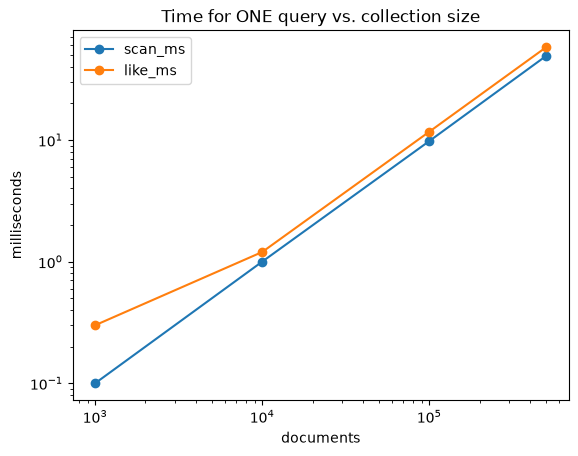

In [14]:
base_texts = list(docs.values())
random.seed(1)

def make_big_corpus(n):
    return [base_texts[i % len(base_texts)] + f" ref{random.randint(0, 10**6)}" for i in range(n)]

sizes = [1_000, 10_000, 100_000, 500_000]
timings = []
for n in sizes:
    corpus = make_big_corpus(n)
    t0 = time.perf_counter()
    scan_hits = [i for i, t in enumerate(corpus) if "rice" in t.lower()]
    scan_ms = (time.perf_counter() - t0) * 1000

    big = sqlite3.connect(":memory:")
    big.execute("CREATE TABLE docs (id INTEGER PRIMARY KEY, text TEXT)")
    big.executemany("INSERT INTO docs(text) VALUES (?)", [(t,) for t in corpus])
    t0 = time.perf_counter()
    like_hits = big.execute("SELECT id FROM docs WHERE text LIKE ?", ("%rice%",)).fetchall()
    like_ms = (time.perf_counter() - t0) * 1000
    timings.append({"documents": n, "scan_ms": round(scan_ms, 1), "like_ms": round(like_ms, 1)})
    print(f"{n:>8,} docs: scan {scan_ms:7.1f} ms, LIKE {like_ms:7.1f} ms")

timing_df = pd.DataFrame(timings)
timing_df.plot(x="documents", y=["scan_ms", "like_ms"], marker="o", logx=True, logy=True,
               title="Time for ONE query vs. collection size")
plt.ylabel("milliseconds"); plt.show()

In [18]:
# TODO: use the LARGEST measurement to estimate how long ONE scan query would take
#       over 1 billion pages, in seconds and in minutes.
largest = timing_df.iloc[-1]
seconds_for_1_billion = (1_000_000_000 / largest["documents"]) * largest["scan_ms"] / 1000
minutes_for_1_billion = seconds_for_1_billion / 60

print(f"Seconds: {seconds_for_1_billion:.2f}")
print(f"Minutes: {minutes_for_1_billion:.2f}")
# print(seconds_for_1_billion)

Seconds: 98.20
Minutes: 1.64


**Answer 6.1** How does the time grow when the collection grows 10 times? What does your estimate say about scanning a web-scale collection for every query?

*Your answer:* When the collection grows 10 times larger, the scanning time also increases by approximately 10 times because the algorithm needs to examine every document. Based on my estimate, scanning 1 billion pages would take around 98.20 seconds (1.64 minutes) for just one query. This shows that scanning every document is inefficient for web-scale search engines, especially when handling many queries.

**Answer 6.2** In one or two sentences, how could a system avoid reading every document at query time? (You will build this in Session 2.)

*Your answer:* A search engine can use an inverted index to store which documents contain each term. This allows the system to retrieve matching documents without scanning the entire collection every time a query is made.

## Part 7. Bonus: Khmer text (optional, 15 min)
Khmer is written without spaces between words. What does that do to the word-based search from Part 3?

In [19]:
khmer_docs = {
    "k1": 'ភ្នំពេញជារាជធានីនៃប្រទេសកម្ពុជា',
    "k2": 'អង្គរវត្តជាប្រាសាទដ៏ធំបំផុតក្នុងពិភពលោក',
    "k3": 'ខ្ញុំចូលចិត្តរៀនសរសេរកម្មវិធី',
}

for q in ["រាជធានី", "ប្រទេស", "កម្មវិធី"]:
    substring_hits = [i for i, t in khmer_docs.items() if q in t]
    word_hits = [i for i, t in khmer_docs.items() if q in t.split()]
    print(f"{q}: substring -> {substring_hits} | whole-word (split on spaces) -> {word_hits}")

រាជធានី: substring -> ['k1'] | whole-word (split on spaces) -> []
ប្រទេស: substring -> ['k1'] | whole-word (split on spaces) -> []
កម្មវិធី: substring -> ['k3'] | whole-word (split on spaces) -> []


**Answer 7.1** Why does whole-word matching find nothing while substring matching finds the documents? Which risk of substring matching (see Part 2) still applies?

*Your answer:* Whole-word matching does not return any results because Khmer words are usually written without spaces between them. As a result, the .split() function treats the entire sentence as one word. Substring matching can find the query because it searches for matching characters within the text. However, it may also return irrelevant results if those characters appear as part of another word.

**Optional challenge:** install a Khmer word segmenter (for example `pip install khmer-nltk`) and segment the three sentences. Does whole-word matching now work? Check the package documentation for the exact function name.

In [22]:
from khmernltk import word_tokenize
for doc_id, text in khmer_docs.items():
    tokens = word_tokenize(text, return_tokens=True)
    print(f"{doc_id}: {tokens}")
    
for q in ["រាជធានី", "ប្រាសាទ", "កម្មវិធី"]:
    word_hits = [
        i for i, t in khmer_docs.items()
        if q in word_tokenize(t, return_tokens=True)
    ]

    print(f"{q}: {word_hits}")

k1: ['ភ្នំពេញ', 'ជា', 'រាជធានី', 'នៃ', 'ប្រទេស', 'កម្ពុជា']
k2: ['អង្គរវត្ត', 'ជា', 'ប្រាសាទ', 'ដ៏', 'ធំ', 'បំផុត', 'ក្នុង', 'ពិភពលោក']
k3: ['ខ្ញុំ', 'ចូលចិត្ត', 'រៀន', 'សរសេរ', 'កម្មវិធី']
រាជធានី: ['k1']
ប្រាសាទ: ['k2']
កម្មវិធី: ['k3']


## Part 8. Reflection (about 10 min)
Write 4 to 6 sentences: *Why is a database query not the same as a search engine? Use at least two results from this lab as evidence, and name one topic from the course roadmap that would fix one of the problems you found.*

*Your reflection:* A database query is not the same as a search engine because it mainly focuses on matching specific text rather than understanding the meaning or relevance of documents. For example, when searching for “cat”, substring matching and SQL LIKE returned irrelevant documents containing words such as “category” and “concatenate”, which reduced precision. Another example is searching for “car”, where none of the methods returned relevant documents because they contained related words such as “automobile” and “vehicle” instead. The performance experiment also showed that scanning a billion documents could take approximately 98.20 seconds for just one query, making this approach inefficient for large-scale searching. To improve search efficiency we can use inverted indexing, which allows search engines to find documents containing specific terms without scanning every document.

---
### Submission checklist
- [ ] All `# TODO` cells completed and the notebook runs from top to bottom without errors
- [ ] All *Answer* cells written in your own words
- [ ] `judgments` filled in, and disagreements with your partner noted in Answer 5.3
- [ ] Project team formed (names and theme sent to the instructor)
- [ ] Notebook saved as `Lab1_<StudentID>.ipynb` and submitted as instructed